In [1]:
import pandas as pd 


In [2]:
df = pd.read_csv("../data/processed/rotulado_v1.csv")  
df.columns = df.columns.str.lower()                       
df.to_csv("../data/processed/rotulado_v1.csv", index=False, encoding="utf-8")  
df.head()                                                 

,descricao,categoria,fonte,banco
0,Compra no débito - Jujuca Bomboniere Sao Berna...,Alimentação,conta,Inter
1,Compra no débito - Drogaria Sao Paulo 194sao B...,Saúde,conta,Inter
2,Pagamento efetuado - Pagamento Fatura - PESSOA,Outros,conta,Inter
3,Compra no débito - Coffee Break Mandu Ltdsao B...,Alimentação,conta,Inter
4,Pix recebido - PESSOA,Transferência,conta,Inter


In [3]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   descricao  138 non-null    str  
 1   categoria  138 non-null    str  
 2   fonte      138 non-null    str  
 3   banco      138 non-null    str  
dtypes: str(4)
memory usage: 4.4 KB


In [4]:
df["categoria"]
df["categoria"].value_counts()

categoria
Transferência    40
Alimentação      20
Compras          20
Outros           14
Mercado          12
Transporte       11
Saúde             8
Moradia           7
Lazer             3
Assinaturas       2
Educação          1
Name: count, dtype: int64

<Axes: ylabel='categoria'>

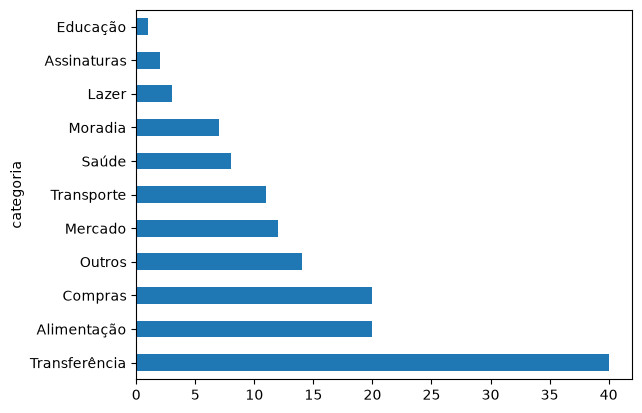

In [5]:
df["categoria"].value_counts().plot(kind="barh")

In [6]:
df[df["categoria"] == "Transporte"]

,descricao,categoria,fonte,banco
22,Compra no débito - Shopping Golden Squaresao B...,Transporte,conta,Inter
27,Compra no débito - Hs Metropole Sbc Sao Bernar...,Transporte,conta,Inter
35,Compra Meio De Transporte - No Estabelecimento...,Transporte,conta,Inter
53,Compra no débito - POSTO MONTE CARLO IGUA,Transporte,conta,Nubank
65,Compra no débito - PAYGO*PHD PARK,Transporte,conta,Nubank
82,Compra no débito - EMV CMT*,Transporte,conta,Nubank
104,PINPAG *AGDESP MUNICIP,Transporte,cartao,Bradesco
105,INPARK,Transporte,cartao,Bradesco
113,StereoCar 01/08,Transporte,cartao,Bradesco
115,SAVOL TOYOTA SBC 01/05,Transporte,cartao,Bradesco


In [7]:
df["tamanho"] = df["descricao"].str.len()
df.groupby("categoria")["tamanho"].mean()

categoria
Alimentação      43.900000
Assinaturas      22.000000
Compras          20.650000
Educação         32.000000
Lazer            22.333333
Mercado          31.916667
Moradia          45.428571
Outros           35.857143
Saúde            26.875000
Transferência    54.800000
Transporte       32.454545
Name: tamanho, dtype: float64

In [8]:
palavras = df["descricao"].str.upper().str.split().explode()
palavras.value_counts().head(15)

descricao
-                121
PESSOA            39
NO                38
COMPRA            37
DÉBITO            36
PIX               35
TRANSFERÊNCIA     32
PELO              31
BRA               28
ENVIADA           25
BERNARDO          23
SAO               22
S.A.              19
DE                18
IP                15
Name: count, dtype: int64

In [10]:
df["fonte"].value_counts()

fonte
conta     86
cartao    52
Name: count, dtype: int64

In [ ]:
pag = df['descricao'].str.contains("CAPPTA *", regex=False)
df[pag]

,descricao,categoria,fonte,banco,tamanho
121,CAPPTA *PESSOA,Lazer,cartao,Bradesco,14


In [22]:
df["tamanho"] = df["descricao"].str.len()

media = df.groupby("categoria")["tamanho"].mean()

media.sort_values(ascending=False)

categoria
Transferência    54.800000
Moradia          45.428571
Alimentação      43.900000
Outros           35.857143
Transporte       32.454545
Educação         32.000000
Mercado          31.916667
Saúde            26.875000
Lazer            22.333333
Assinaturas      22.000000
Compras          20.650000
Name: tamanho, dtype: float64